<a href="https://colab.research.google.com/github/facundoVega/ProcesamientoDelHabla/blob/main/TP2-Procesamiento-PDF/Horacio_Facundo_Vega_TP2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1.- Adquizición y metadatos**

---



In [22]:
#Instalo las dependencias necesarias.
!pip install pymupdf pandas pdfplumber nltk requests -q

Descargo el PDF desde el link público y lo guardo en el disco con el nombre "indicador_servicios_publicos.pdf"

In [23]:
import requests
import os

url = "https://www.indec.gob.ar/uploads/informesdeprensa/issp_10_263259353882.pdf"
nombre_archivo = "indicador_servicios_publicos.pdf"

respuesta = requests.get(
    url,
    allow_redirects=False,
    timeout=30
    )

print("Código de estado HTTP:", respuesta.status_code)


with open(nombre_archivo, "wb") as f:
  f.write(respuesta.content)

tamano_kb = os.path.getsize(nombre_archivo) /1024
print(f"Archivo guardado como '{nombre_archivo}' ({tamano_kb:-1f} KB)")



Código de estado HTTP: 200
Archivo guardado como 'indicador_servicios_publicos.pdf' (1083.150391 KB)


**Importo el PDF**

Ahora que tengo el archivo en disco, voy a abrirlo usando la liberia PyMuPDF

In [24]:
import pymupdf

doc = pymupdf.open(nombre_archivo)

print("Tipo de objeto: ", type(doc))
print("Cantidad de paginas: ", doc.page_count)


Tipo de objeto:  <class 'pymupdf.Document'>
Cantidad de paginas:  13




En el snippet anterior, importamos el PDF y lo abrimos. Pudimos confirmar que el PDF tiene 13 paginas y el tipo de objeto es "pymupdf.Document". Esta clase de la libreria PyMuPDF representa un documento PDF abierto en memoria, por lo que nuestro PDF ya esta listo para que podamos interactuar con el, en este colab.

**Muestro la metadata del PDF.**

In [25]:
metadata = doc.metadata

metadata

{'format': 'PDF 1.7',
 'title': 'Indicador sintético de servicios públicos. Julio de 2026',
 'author': 'Instituto Nacional de Estadística y Censos (INDEC)',
 'subject': 'Indicador sintético de servicios públicos',
 'keywords': '',
 'creator': 'Adobe InDesign 21.6 (Windows)',
 'producer': 'Adobe PDF Library 18.0',
 'creationDate': "D:20261005155606-03'00'",
 'modDate': "D:20261008142017-03'00'",
 'trapped': '',
 'encryption': None}

# **2.- Análisis estructural del texto**

---



Al trabajar con la libreria "pymupdf", la función "get_text()" aplicada sobre cada página del documento  permite obtener el texto del PDF sin aplicar transformacion, limpieza ni estructuras adicionales. Es decir de la manera mas cruda.

In [26]:
texto_crudo = ""


for i, pagina in enumerate(doc):
  #texto_crudo += f"\n\n-- PÁGINA {i+1} --  \n\n"
  texto_crudo += pagina.get_text()

print(texto_crudo)

Indicador sintético de servicios 
públicos
Julio de 2026
Servicios
Vol. 10, n° 16
ISSN 2545-6636
Informes técnicos / Vol. 10, n° 248
Signos convencionales: 
*	
Dato provisorio
e	
Dato estimado por extrapolación, proyección
i 	
Dato estimado por imputación
u 	
Dato de calidad inferior al estándar 
-	
Cero absoluto
.	
Dato no registrado
...	
Dato no disponible a la fecha de presentación de los resultados
///	
Dato que no corresponde presentar 
s	
Dato confidencial por aplicación de las reglas del secreto estadístico
INDECArgentina
Publicaciones del INDEC
Las publicaciones editadas por el Instituto Nacional de Estadística y Censos 
pueden ser consultadas en www.indec.gob.ar y en el Centro Estadístico de 
Servicios, ubicado en Av. Presidente Julio A. Roca 609 C1067ABB, Ciudad 
Autónoma de Buenos Aires, Argentina. El horario de atención al público es 
de 9:30 a 16:00.
También pueden solicitarse al teléfono (54-11) 5031-4632 
Correo electrónico: ces@indec.gob.ar
Sitio web: www.indec.gob.ar	


In [27]:
print(repr(texto_crudo))

'Indicador sintético de servicios \npúblicos\nJulio de 2026\nServicios\nVol. 10, n° 16\nISSN 2545-6636\nInformes técnicos / Vol. 10, n° 248\nSignos convencionales: \n*\t\nDato provisorio\ne\t\nDato estimado por extrapolación, proyección\ni \t\nDato estimado por imputación\nu \t\nDato de calidad inferior al estándar \n-\t\nCero absoluto\n.\t\nDato no registrado\n...\t\nDato no disponible a la fecha de presentación de los resultados\n///\t\nDato que no corresponde presentar \ns\t\nDato confidencial por aplicación de las reglas del secreto estadístico\nINDECArgentina\nPublicaciones del INDEC\nLas publicaciones editadas por el Instituto Nacional de Estadística y Censos \npueden ser consultadas en www.indec.gob.ar y en el Centro Estadístico de \nServicios, ubicado en Av. Presidente Julio A. Roca 609 C1067ABB, Ciudad \nAutónoma de Buenos Aires, Argentina. El horario de atención al público es \nde 9:30 a 16:00.\nTambién pueden solicitarse al teléfono (54-11) 5031-4632 \nCorreo electrónico: ce

**Analisis de separadores.**

Para este analisis se observó el texto crudo obtenido en la celda anterior y el PDF real. De esta manera se puede entender como esta estructurado el PDF original y como el texto crudo replica esa estructura.

El PDF presenta una organización repetitiva por páginas. Cada página contiene en general una tabla o figura estadística, acompañada por su análisis.

En principio, en el Índice del texto crudo se observan  secuencias repetidas de puntos que seperan los titulos de las páginas.

A partir de la visualización del texto crudo podemos observar que el delimitador mas utilizado es el salto de linea "/n" el cual se utiliza para denominar titulos y para la separación entre parrafos.

Algo importante tambien a destacar es que, gracias a la buena organizacion del PDF,  el texto extraído conserva información útil sobre la paginación. Al final de cada página aparece un identificador con el formato "X/13" (por ejemplo, "1/13", "2/13", etc), lo cual indica el número de página actual y la cantidad total de páginas del documento. Esto es especialmente útil para identificar los límites entre páginas al momento de trabajar con el texto crudo.




# 3.- **Extracción de datos tabulares**

---



Para extraer una tabla del PDF  utilizare la librería PDFplumber. Por ende luego de importar la librería procedo a  abrir el PDF con PDFPlumber entonces puedo empezar a interactuar con el PDF utilizando este modulo.  

In [28]:
#importo pdf pluber y abro el PDF con este modulo.
import pdfplumber

pdf_plumber = pdfplumber.open(nombre_archivo)

print("Tipo de Objeto", type(pdf_plumber))
print("Cantidad de páginas", doc.page_count)

Tipo de Objeto <class 'pdfplumber.pdf.PDF'>
Cantidad de páginas 13


Mediante el uso del método "extract_table()" de PDFPlumber obtendre la tabla de la página 9 de mi PDF. Este método devuelve la tabla como una lista de listas , por lo que habra que hacer alguna manipulación subsiguiente para convertirla a un DataFrame de Pandas.

In [29]:
#Extraigo la tabla cruda de la página 9 del documento
pagina = pdf_plumber.pages[8]
tabla_cruda = pagina.extract_table()



In [30]:
#Verifico que la tabla haya sido extraída correctamente
print("Tipo de dato:", type(tabla_cruda))
print("Cantidad de filas:", len(tabla_cruda))
print("Primeras 3 filas")
for fila in tabla_cruda[:5]:
  print(fila)


Tipo de dato: <class 'list'>
Cantidad de filas: 21
Primeras 3 filas
['Período', None, 'ISSP\nnivel\ngeneral', 'Electricidad,\ngas y\nagua', 'Recolección\nde\nresiduos', 'Transporte\nde\npasajeros', 'Transporte\nde\ncarga (1)', 'Peajes', 'Servicio\nde\ncorreo', 'Telefonía']
['', '', '%', None, None, None, None, None, None, None]
['2025*', 'Enero', '1,5', '6,6', '0,2', '-1,5', '0,6', '0,8', '4,3', '0,1']
['', 'Febrero', '1,6', '4,4', '5,6', '0,4', '-3,8', '-0,4', '0,3', '0,4']
['', 'Marzo', '-2,6', '-8,5', '-3,4', '0,8', '-19,5', '-2,0', '4,0', '-0,3']


Ahora que vemos como esta estructurada la tabla cruda vamos a necesitar hacer los siguientes ajustes para convertirla a un Dataframe de pandas.



1.   Eliminaremos los saltos de linea en los nombres de columna.
2.   Añadiremos la columna "mes" como segunda columna de la tabla.
3.   Completaremos la columna "Período" con el año correspondiente de cada fila.
3.   Eliminaremos la segunda fila , ya que no aporta datos significativos.



In [31]:
#Elimino los saltos de linea en los nombres de columna
tabla_cruda[0] = [
    ' '.join(celda.split()) if isinstance(celda, str) else celda
    for celda in tabla_cruda[0]
]

print(tabla_cruda[0])

['Período', None, 'ISSP nivel general', 'Electricidad, gas y agua', 'Recolección de residuos', 'Transporte de pasajeros', 'Transporte de carga (1)', 'Peajes', 'Servicio de correo', 'Telefonía']


In [32]:
#Añadimos la columna "mes" como segunda columna de la tabla
tabla_cruda[0][1] = "Mes"

print(tabla_cruda[0][1])
print(tabla_cruda[0])

Mes
['Período', 'Mes', 'ISSP nivel general', 'Electricidad, gas y agua', 'Recolección de residuos', 'Transporte de pasajeros', 'Transporte de carga (1)', 'Peajes', 'Servicio de correo', 'Telefonía']


In [33]:
#Completaremos la columna "Período" con el año correspondiente de cada fila.
anio_actual = ""

for fila in tabla_cruda[2:]:
  if fila[0] != "":
    anio_actual = fila[0].replace("*", "")
    fila[0] = anio_actual
  else:
    fila[0] = anio_actual

for fila in tabla_cruda:
  print(fila)

['Período', 'Mes', 'ISSP nivel general', 'Electricidad, gas y agua', 'Recolección de residuos', 'Transporte de pasajeros', 'Transporte de carga (1)', 'Peajes', 'Servicio de correo', 'Telefonía']
['', '', '%', None, None, None, None, None, None, None]
['2025', 'Enero', '1,5', '6,6', '0,2', '-1,5', '0,6', '0,8', '4,3', '0,1']
['2025', 'Febrero', '1,6', '4,4', '5,6', '0,4', '-3,8', '-0,4', '0,3', '0,4']
['2025', 'Marzo', '-2,6', '-8,5', '-3,4', '0,8', '-19,5', '-2,0', '4,0', '-0,3']
['2025', 'Abril', '0,1', '-0,6', '3,4', '-0,3', '8,9', '-2,3', '2,1', '0,1']
['2025', 'Mayo', '-1,0', '-4,6', '3,0', '-1,5', '6,9', '2,0', '-4,1', '0,1']
['2025', 'Junio', '1,3', '6,5', '-4,3', '0,2', '0,1', '-1,2', '-1,3', '0,1']
['2025', 'Julio', '0,6', '-0,3', '2,0', '2,1', '9,1', '1,3', '0,1', '0,4']
['2025', 'Agosto', '-0,1', '-0,7', '-1,1', '-0,5', '-3,1', '0,2', '2,1', '0,4']
['2025', 'Septiembre', '0,2', '1,1', '-0,1', '-0,3', '-2,8', '-1,1', '1,6', '0,0']
['2025', 'Octubre', '-1,0', '-3,4', '0,4', '-0

In [34]:
#Elimino la segunda fila , ya que no aporta datos significativo
tabla_cruda.pop(1)
for fila in tabla_cruda[:3]:
  print(fila)

['Período', 'Mes', 'ISSP nivel general', 'Electricidad, gas y agua', 'Recolección de residuos', 'Transporte de pasajeros', 'Transporte de carga (1)', 'Peajes', 'Servicio de correo', 'Telefonía']
['2025', 'Enero', '1,5', '6,6', '0,2', '-1,5', '0,6', '0,8', '4,3', '0,1']
['2025', 'Febrero', '1,6', '4,4', '5,6', '0,4', '-3,8', '-0,4', '0,3', '0,4']


**Ahora si con los datos limpios transformo la tabla cruda en un dataframe de pandas.**

In [35]:
import pandas as pd

encabezados = tabla_cruda[0]
filas_datos = tabla_cruda[1:]

df = pd.DataFrame(filas_datos, columns=encabezados)
df.tail()

,Período,Mes,ISSP nivel general,"Electricidad, gas y agua",Recolección de residuos,Transporte de pasajeros,Transporte de carga (1),Peajes,Servicio de correo,Telefonía
14,2026,Marzo,"0,9","0,2","4,2","1,9","5,9","0,6","15,7","0,2"
15,2026,Abril,"-0,2","1,4","3,1","-5,3","0,4","0,1","-4,4","-0,1"
16,2026,Mayo,"-0,3","-0,1","-5,1","-2,4","6,0","1,6","-2,1","0,3"
17,2026,Junio,"-0,5","-1,8","5,7","-3,0","-1,2","-2,7","1,5","0,1"
18,2026,Julio,"-0,3","-0,1","-6,2","1,3","-4,5","-2,1","-10,5","0,3"


# **4.- Análisis de frecuencias (NLP Básico)**

---



1.-**Tokenización:** Extraigo el texto y lo convierto a minusculas

In [36]:
#Extraigo una página con texto narrativo y convierto el texo en minusculas
texto_pagina = pdf_plumber.pages[10].extract_text()
texto_minusculas = texto_pagina.lower()
print(texto_minusculas)

enlace a más detalles
pueden consultarse más detalles de las series que componen el issp, desde enero de 2012 hasta el período de
referencia del presente informe, en los cuadros que se encuentran en formato digital disponibles en: https://www.
indec.gob.ar/ftp/cuadros/economia/sh_issp_2026.xls
índice de cuadros web
cuadro 1. indicador sintético de servicios públicos, índice nivel general. serie original, desestacionalizada y
tendencia-ciclo, base 2004=100, en números índice y variación porcentual
cuadro 2. indicador sintético de servicios públicos, índice nivel general y sector de actividad económica. serie
original, base 2004=100, en números índice y variación porcentual respecto al mismo mes del año anterior
cuadro 3. indicador sintético de servicios públicos, índice nivel general y sector de actividad económica. serie
desestacionalizada, base 2004=100, en números índice y variación porcentual respecto al mes anterior
cuadro 4. indicador sintético de servicios públicos, índice nivel 

In [37]:
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')



[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [38]:
#Tokenizacion del texto
from nltk.tokenize import word_tokenize

tokens =  word_tokenize(texto_minusculas, language='spanish')

print(tokens[:50])

['enlace', 'a', 'más', 'detalles', 'pueden', 'consultarse', 'más', 'detalles', 'de', 'las', 'series', 'que', 'componen', 'el', 'issp', ',', 'desde', 'enero', 'de', '2012', 'hasta', 'el', 'período', 'de', 'referencia', 'del', 'presente', 'informe', ',', 'en', 'los', 'cuadros', 'que', 'se', 'encuentran', 'en', 'formato', 'digital', 'disponibles', 'en', ':', 'https', ':', '//www', '.', 'indec.gob.ar/ftp/cuadros/economia/sh_issp_2026.xls', 'índice', 'de', 'cuadros', 'web']


2.- **Limpieza:** Elimino las stop words y los signos de puntuación

In [39]:
#Cargo las stopwords de NLTK
from nltk.corpus import stopwords
stop_words = set(stopwords.words('spanish'))


**Elimino las stop words y los signos de puntuación**

In [40]:
tokens_limpios = [
    token for token in tokens
    if token.isalpha() and token not in stop_words
]

print(tokens_limpios[:50])

['enlace', 'detalles', 'pueden', 'consultarse', 'detalles', 'series', 'componen', 'issp', 'enero', 'período', 'referencia', 'presente', 'informe', 'cuadros', 'encuentran', 'formato', 'digital', 'disponibles', 'https', 'índice', 'cuadros', 'web', 'cuadro', 'indicador', 'sintético', 'servicios', 'públicos', 'índice', 'nivel', 'general', 'serie', 'original', 'desestacionalizada', 'base', 'números', 'índice', 'variación', 'porcentual', 'cuadro', 'indicador', 'sintético', 'servicios', 'públicos', 'índice', 'nivel', 'general', 'sector', 'actividad', 'económica', 'serie']


3.- **Visualización** Genero un gráfico de barras que muestre las 5 palabras mas frecuentes

In [41]:
#calculo las frecuencias de las palabras
from collections import Counter

frecuencias = Counter(tokens_limpios)

top_15 = frecuencias.most_common(15)

print(top_15)

[('cuadro', 17), ('índice', 9), ('servicios', 6), ('miles', 6), ('indicador', 5), ('sintético', 5), ('públicos', 5), ('servicio', 5), ('unidades', 5), ('nivel', 4), ('general', 4), ('serie', 4), ('base', 4), ('números', 4), ('variación', 4)]


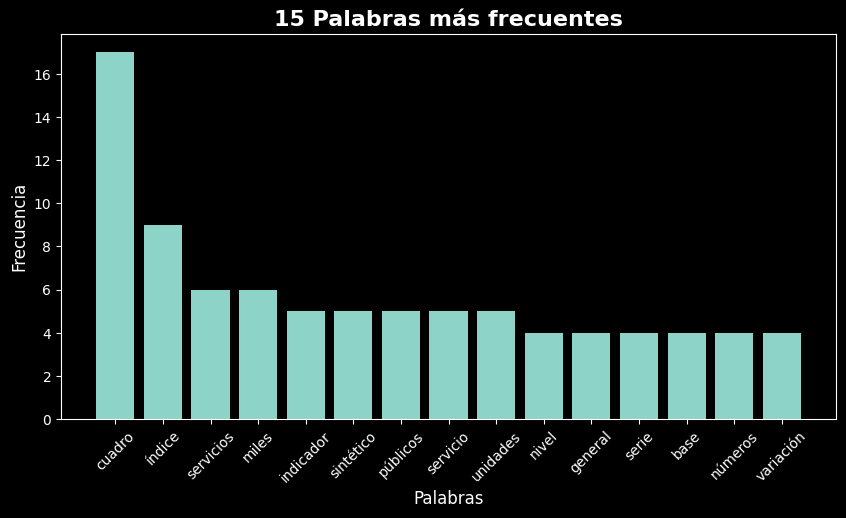

In [42]:
#Creo el gráficod de barras
import matplotlib.pyplot as plt

plt.style.use('dark_background')

palabras = [x[0] for x in top_15]
cantidades = [x[1] for x in top_15]

plt.figure(figsize=(10,5))
plt.bar(palabras, cantidades)

plt.title("15 Palabras más frecuentes", fontsize=16, fontweight='bold')
plt.xlabel("Palabras", fontsize=12)
plt.ylabel("Frecuencia", fontsize=12)

plt.xticks(rotation=45)
plt.show()




**Análisis de Tokens mas frecuentes**


* En esta visualización no me surgieron tokens que pueda considerar stop words. Todos los tokens que aparecen aportan sentido  y pueden ser utilizados para entender de que esta hablando el PDF en cuestión.

* Para el caso de las palabras "servicio" y "servicios" deberían considerarse como un mismo término si se necesitara un análisis mas avanzado, ya que el significado semántico de los mismos es igual anque su forma escrita sea ligeramente diferente. Quiza podría ser mas útil aplicar lematización para transformar las palabras a su forma base, y entonces estas dos palabras pertenecerían al mismo token.

* Particularmente esta página de mi PDF habla de como esta organizado el informe y es por eso, que palabras como "cuadro", "índice" y "servicios" aparecen tan frecuentemente, ya que es justamente el contenido principal del PDF del INDEC que utilize para este trabajo.

* Por ultimo la presencia frecuente de palabras como "servicio", "servicios", "publico" permite inferir  que el tema principal del PDF esta relacionado con medición o evaluación de los servicios públicos



# **FUENTES**

---

Las fuentes utilizadas para este TP fueron 3:
* En primer lugar se utilizo como base el video compartido por la docente sobre como manejar e importar PDFs a nuestro entorno de colab , en la clase correspondiente a la semana 1.

* En segundo lugar, gran parte del código utilizado en este TP se tomo del taller de manejo de PDFs impartido por la docente en la clase de la semana 3

* Por ultimo, se trabajó con Github copilot, el cual al estar en un entorno corporativo , no puedo compartir los prompts por políticas de privacidad. Sin embargo, paso a detallar en que pedí asistencia:
  * Le pedi ayuda con la visualizacion de matplotlib de las 15 palabras mas frecuentes.
  * Le pedi ayuda con los snippets de código utilizados para formatear la tabla obtenida del PDF antes de convertirla en un DataFrame de Pandas. Esto fue como parte del desarrollo del punto 3 de este TP.

*Todo el código presente en este colab fue transcrito por mi y guardo total responsabilidad por la funcionalidad o no de los mismos en la ejecución de este colab.*